In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

BASE = (
    Path("experiment_v2")
    if Path("experiment_v2/data").is_dir()
    else Path(".")
)

DATA_PATH = BASE / "data/processed/malta_daily_observations.nc"

data = xr.open_dataset(DATA_PATH)

print("Loaded:", DATA_PATH.resolve())
display(data)

Matplotlib is building the font cache; this may take a moment.


Loaded: /Users/alangatt/git/mcast.pages.chl_prediction/experiment_v2/data/processed/malta_daily_observations.nc


<xarray.Dataset> Size: 5GB
Dimensions:         (time: 6575, latitude: 133, longitude: 101)
Coordinates:
  * time            (time) datetime64[ns] 53kB 2008-01-01 ... 2025-12-31
  * latitude        (latitude) float32 532B 35.55 35.56 35.57 ... 36.88 36.89
  * longitude       (longitude) float32 404B 13.91 13.92 13.93 ... 15.18 15.19
Data variables: (12/17)
    chl             (time, latitude, longitude) float32 353MB ...
    sst_c           (time, latitude, longitude) float32 353MB ...
    wind_u_asc      (time, latitude, longitude) float32 353MB ...
    wind_v_asc      (time, latitude, longitude) float32 353MB ...
    wind_speed_asc  (time, latitude, longitude) float32 353MB ...
    wind_time_asc   (time, latitude, longitude) datetime64[ns] 707MB ...
    ...              ...
    wind_qc_des     (time, latitude, longitude) float32 353MB ...
    chl_valid       (time, latitude, longitude) uint8 88MB ...
    sst_valid       (time, latitude, longitude) uint8 88MB ...
    wind_asc_valid  (time, latitude, longitude) uint8 88MB ...
    wind_des_valid  (time, latitude, longitude) uint8 88MB ...
    wind_any_valid  (time, latitude, longitude) uint8 88MB ...
Attributes:
    description:           Daily L3 CHL, SST and ASCAT wind on the CHL grid
    spatial_mapping:       Nearest source cell within half-cell tolerance
    time_definition:       UTC daily labels; wind acquisition timestamps reta...
    temporal_gap_filling:  None
    source_files:          {"chl": "data/chl_l3_l4_comparison/chl_L3_2008-01-...

Included cells: 12,378 / 13,433


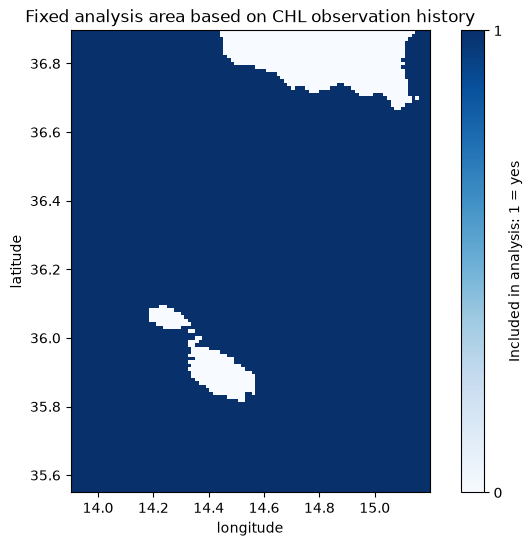

In [2]:
analysis_mask = (data["chl_valid"] == 1).any(dim="time")

included = int(analysis_mask.sum().item())
print(f"Included cells: {included:,} / {analysis_mask.size:,}")

fig, ax = plt.subplots(figsize=(8, 6))

analysis_mask.astype("uint8").plot(
    ax=ax,
    x="longitude",
    y="latitude",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kwargs={
        "ticks": [0, 1],
        "label": "Included in analysis: 1 = yes",
    },
)

ax.set_aspect(
    1 / np.cos(np.deg2rad(float(data.latitude.mean().item())))
)
ax.set_title("Fixed analysis area based on CHL observation history")
plt.show()

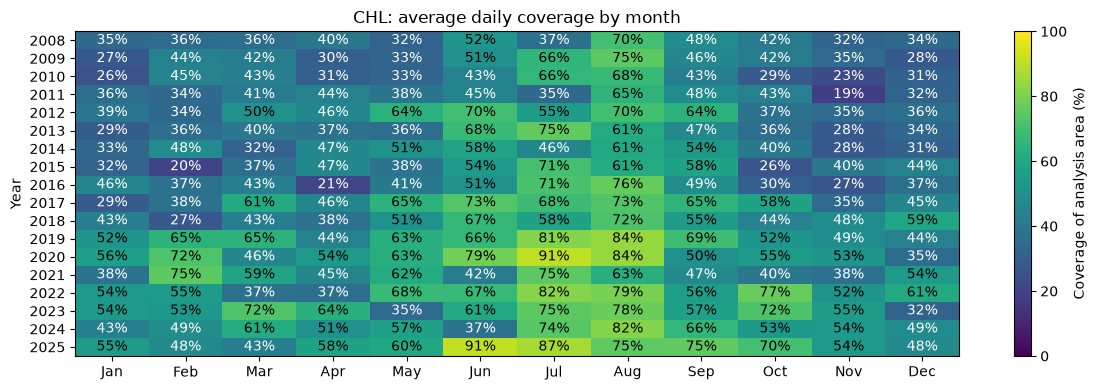

In [3]:
daily_chl_coverage = (
    100
    * ((data["chl_valid"] == 1) & analysis_mask).sum(
        dim=["latitude", "longitude"]
    )
    / included
)

monthly = daily_chl_coverage.resample(time="MS").mean()

table = monthly.to_series().to_frame("Coverage")
table["Year"] = table.index.year
table["Month"] = table.index.month
table = table.pivot(index="Year", columns="Month", values="Coverage")

fig, ax = plt.subplots(figsize=(12, 4))

image = ax.imshow(
    table.values,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100,
)

ax.set_xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
])
ax.set_yticks(range(len(table)), table.index)

for (row, column), value in np.ndenumerate(table.values):
    ax.text(
        column, row, f"{value:.0f}%",
        ha="center", va="center",
        color="white" if value < 50 else "black",
    )

ax.set_title("CHL: average daily coverage by month")
ax.set_ylabel("Year")
fig.colorbar(image, ax=ax, label="Coverage of analysis area (%)")
plt.tight_layout()
plt.show()

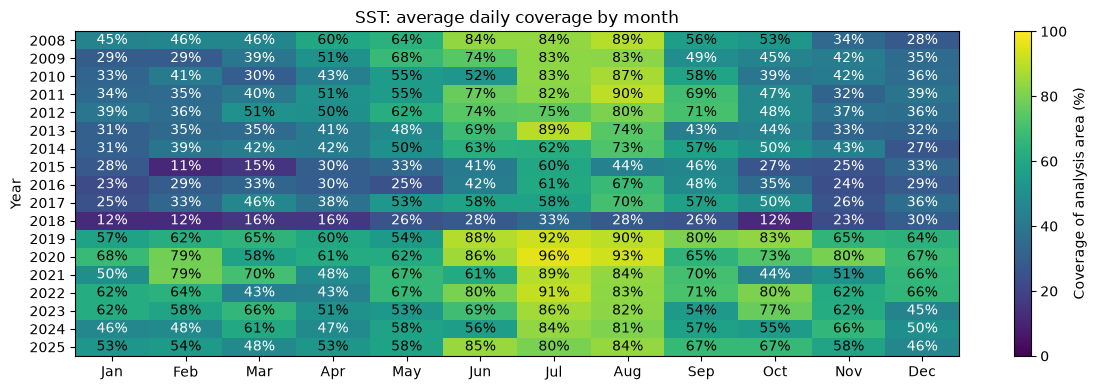

In [4]:
daily_sst_coverage = (
    100
    * ((data["sst_valid"] == 1) & analysis_mask).sum(
        dim=["latitude", "longitude"]
    )
    / included
)

monthly = daily_sst_coverage.resample(time="MS").mean()

table = monthly.to_series().to_frame("Coverage")
table["Year"] = table.index.year
table["Month"] = table.index.month
table = table.pivot(index="Year", columns="Month", values="Coverage")

fig, ax = plt.subplots(figsize=(12, 4))

image = ax.imshow(
    table.values,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100,
)

ax.set_xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
])
ax.set_yticks(range(len(table)), table.index)

for (row, column), value in np.ndenumerate(table.values):
    ax.text(
        column, row, f"{value:.0f}%",
        ha="center", va="center",
        color="white" if value < 50 else "black",
    )

ax.set_title("SST: average daily coverage by month")
ax.set_ylabel("Year")
fig.colorbar(image, ax=ax, label="Coverage of analysis area (%)")
plt.tight_layout()
plt.show()

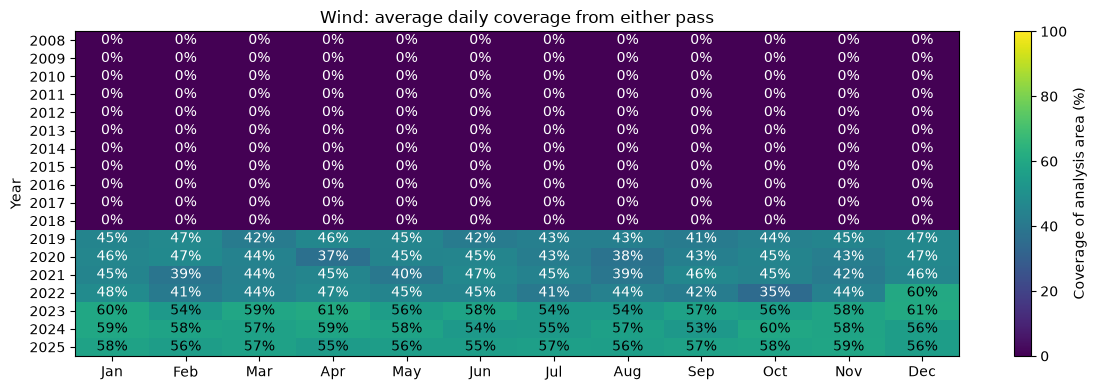

In [5]:
daily_wind_coverage = (
    100
    * ((data["wind_any_valid"] == 1) & analysis_mask).sum(
        dim=["latitude", "longitude"]
    )
    / included
)

monthly = daily_wind_coverage.resample(time="MS").mean()

table = monthly.to_series().to_frame("Coverage")
table["Year"] = table.index.year
table["Month"] = table.index.month
table = table.pivot(index="Year", columns="Month", values="Coverage")

fig, ax = plt.subplots(figsize=(12, 4))

image = ax.imshow(
    table.values,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100,
)

ax.set_xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
])
ax.set_yticks(range(len(table)), table.index)

for (row, column), value in np.ndenumerate(table.values):
    ax.text(
        column, row, f"{value:.0f}%",
        ha="center", va="center",
        color="white" if value < 50 else "black",
    )

ax.set_title("Wind: average daily coverage from either pass")
ax.set_ylabel("Year")
fig.colorbar(image, ax=ax, label="Coverage of analysis area (%)")
plt.tight_layout()
plt.show()

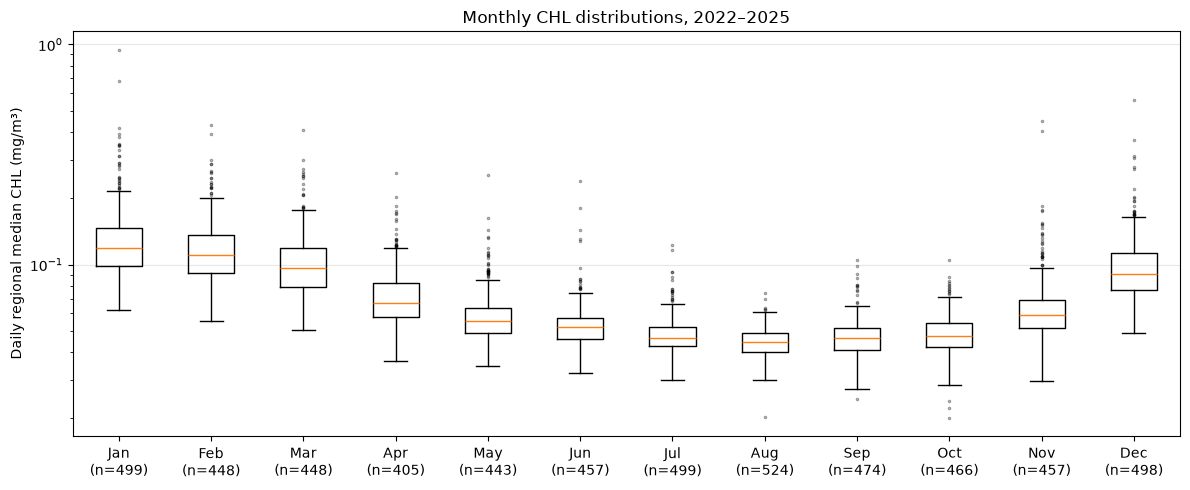

In [6]:
has_observations = (
    (data["chl_valid"] == 1) & analysis_mask
).any(dim=["latitude", "longitude"])

daily_chl = (
    data["chl"]
    .where(analysis_mask)
    .isel(time=np.flatnonzero(has_observations.values))
    .median(dim=["latitude", "longitude"], skipna=True)
    .to_series()
)

groups = [
    daily_chl[daily_chl.index.month == month].values
    for month in range(1, 13)
]

months = pd.date_range(
    "2000-01-01", periods=12, freq="MS"
).strftime("%b")

fig, ax = plt.subplots(figsize=(12, 5))

ax.boxplot(
    groups,
    flierprops={"marker": ".", "markersize": 3, "alpha": 0.4},
)

ax.set_xticks(range(1, 13), [
    f"{month}\n(n={len(values)})"
    for month, values in zip(months, groups)
])
ax.set_yscale("log")
ax.set_ylabel("Daily regional median CHL (mg/m³)")
ax.set_title("Monthly CHL distributions, 2022–2025")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

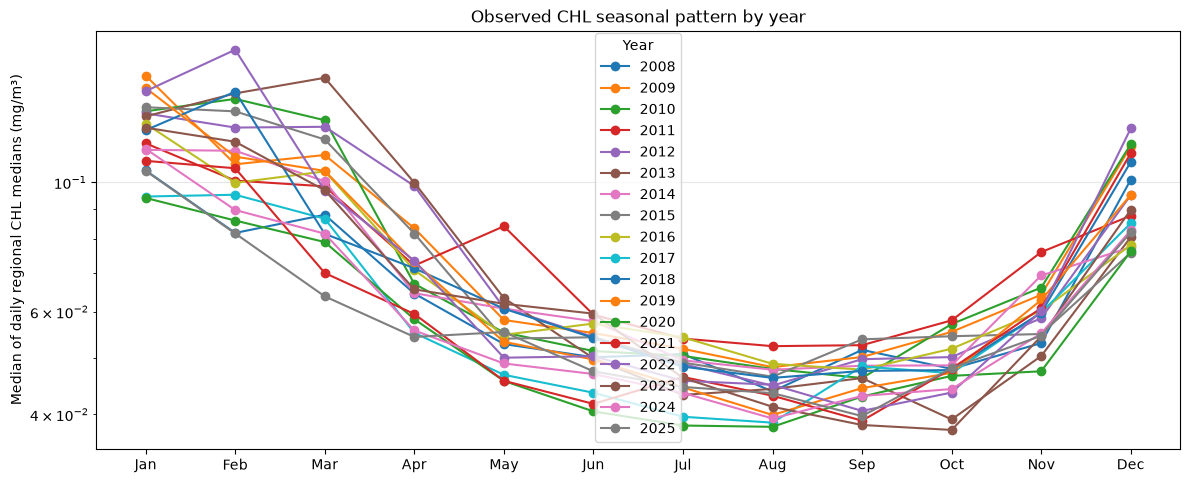

In [7]:
monthly_chl = daily_chl.resample("MS").median()

fig, ax = plt.subplots(figsize=(12, 5))

for year in sorted(monthly_chl.index.year.unique()):
    values = monthly_chl[monthly_chl.index.year == year]
    ax.plot(
        values.index.month,
        values.values,
        marker="o",
        label=str(year),
    )

ax.set_xticks(range(1, 13), months)
ax.set_yscale("log")
ax.set_ylabel("Median of daily regional CHL medians (mg/m³)")
ax.set_title("Observed CHL seasonal pattern by year")
ax.legend(title="Year")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

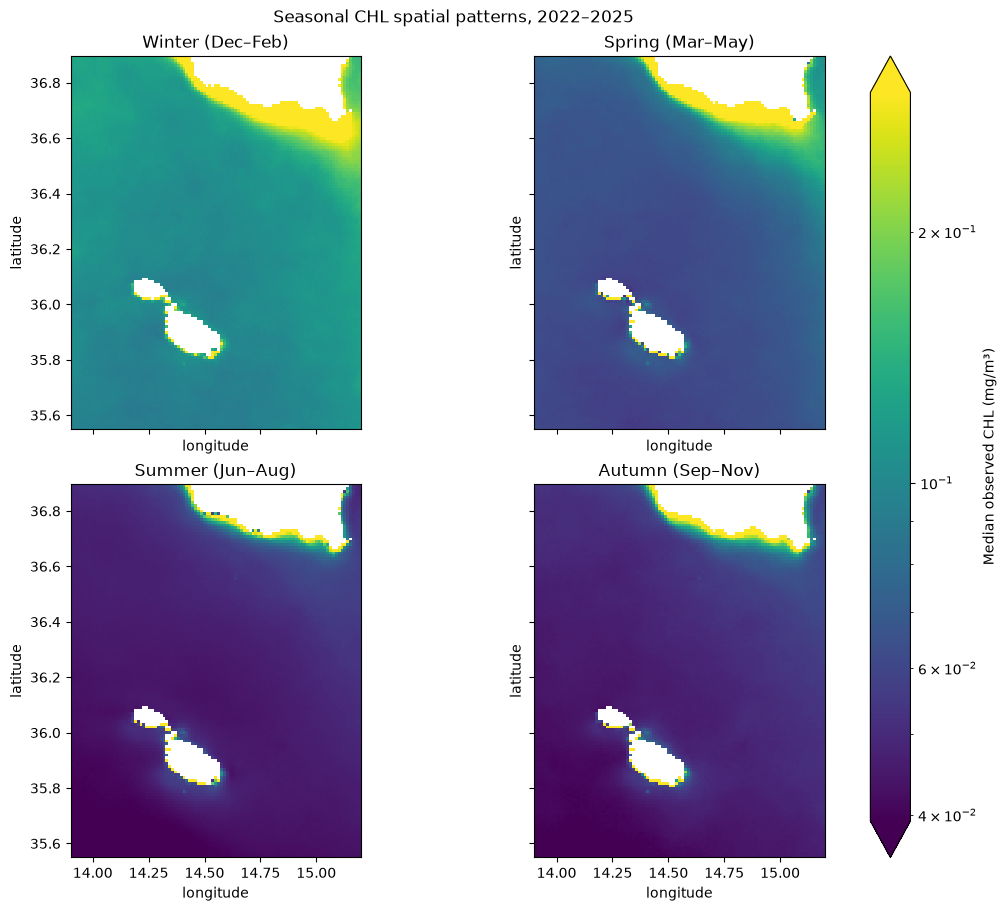

In [8]:
from matplotlib.colors import LogNorm

seasonal_chl = (
    data["chl"]
    .where(analysis_mask & (data["chl"] > 0))
    .groupby("time.season")
    .median(dim="time", skipna=True)
)

# Shared scale; values outside these limits use the end colours.
vmin, vmax = np.nanpercentile(seasonal_chl.values, [2, 98])

fig, axes = plt.subplots(
    2, 2, figsize=(11, 9), sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, season, title in zip(
    axes.flat,
    ["DJF", "MAM", "JJA", "SON"],
    ["Winter (Dec–Feb)", "Spring (Mar–May)",
     "Summer (Jun–Aug)", "Autumn (Sep–Nov)"],
):
    image = seasonal_chl.sel(season=season).plot.pcolormesh(
        ax=ax,
        x="longitude",
        y="latitude",
        cmap="viridis",
        norm=LogNorm(vmin=vmin, vmax=vmax),
        add_colorbar=False,
    )
    ax.set_title(title)
    ax.set_aspect(1 / np.cos(np.deg2rad(float(data.latitude.mean()))))

fig.colorbar(
    image, ax=axes.ravel().tolist(),
    label="Median observed CHL (mg/m³)", extend="both",
)
fig.suptitle("Seasonal CHL spatial patterns, 2022–2025")
plt.show()

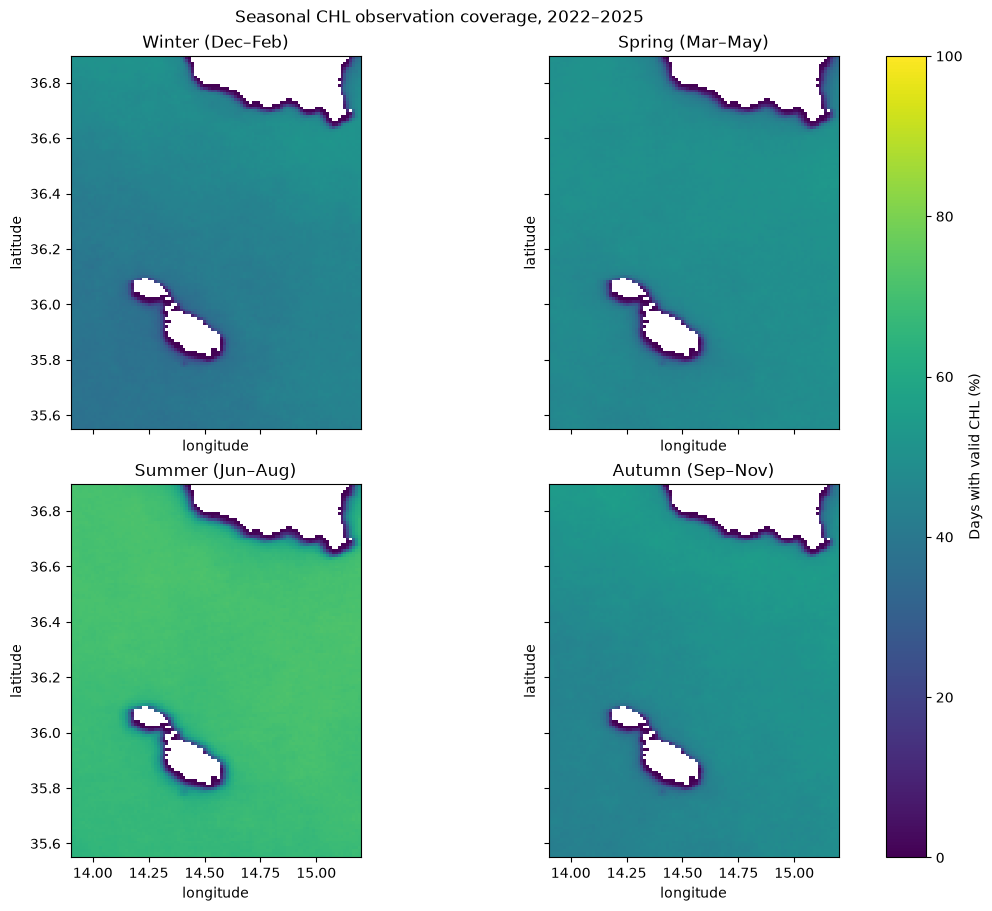

In [9]:
seasonal_coverage = (
    (data["chl_valid"] == 1)
    .groupby("time.season")
    .mean(dim="time")
    .where(analysis_mask)
    * 100
)

fig, axes = plt.subplots(
    2, 2, figsize=(11, 9), sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, season, title in zip(
    axes.flat,
    ["DJF", "MAM", "JJA", "SON"],
    ["Winter (Dec–Feb)", "Spring (Mar–May)",
     "Summer (Jun–Aug)", "Autumn (Sep–Nov)"],
):
    image = seasonal_coverage.sel(season=season).plot.pcolormesh(
        ax=ax,
        x="longitude",
        y="latitude",
        cmap="viridis",
        vmin=0,
        vmax=100,
        add_colorbar=False,
    )
    ax.set_title(title)
    ax.set_aspect(1 / np.cos(np.deg2rad(float(data.latitude.mean()))))

fig.colorbar(
    image, ax=axes.ravel().tolist(),
    label="Days with valid CHL (%)",
)
fig.suptitle("Seasonal CHL observation coverage, 2022–2025")
plt.show()

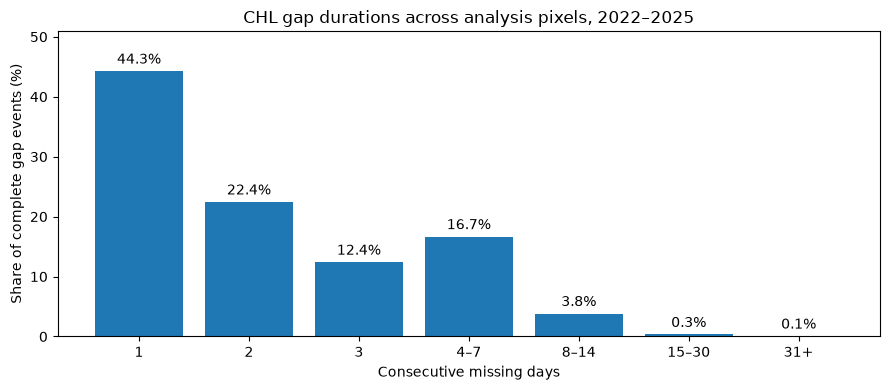

In [10]:
# Rows are analysis pixels; columns are consecutive daily dates.
observed = (
    data["chl_valid"].values[:, analysis_mask.values] == 1
).T

missing = ~observed

# Locate the start and end of every missing run.
changes = np.diff(
    np.pad(missing, ((0, 0), (1, 1)), constant_values=False)
    .astype(np.int8),
    axis=1,
)

_, starts = np.where(changes == 1)
_, ends = np.where(changes == -1)

bounded = (starts > 0) & (ends < observed.shape[1])
gap_lengths = ends[bounded] - starts[bounded]

labels = ["1", "2", "3", "4–7", "8–14", "15–30", "31+"]
gap_groups = pd.cut(
    gap_lengths,
    bins=[0, 1, 2, 3, 7, 14, 30, np.inf],
    labels=labels,
)
gap_counts = pd.Series(gap_groups).value_counts(sort=False)
gap_percent = 100 * gap_counts / gap_counts.sum()

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, gap_percent.values)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Consecutive missing days")
ax.set_ylabel("Share of complete gap events (%)")
ax.set_title("CHL gap durations across analysis pixels, 2022–2025")
ax.set_ylim(0, gap_percent.max() * 1.15)
plt.tight_layout()
plt.show()

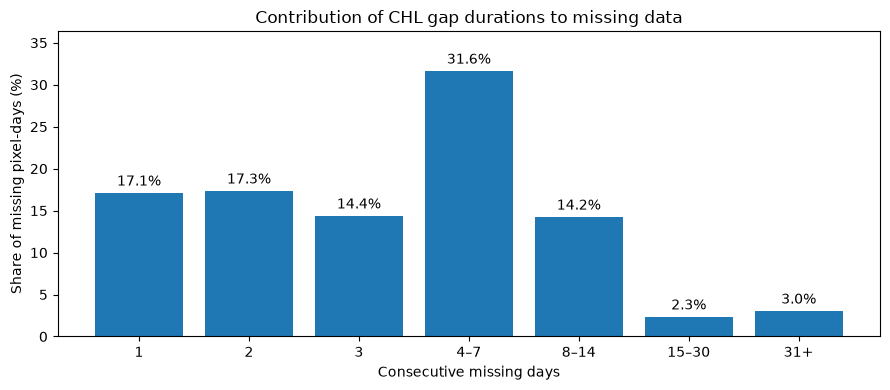

In [11]:
missing_days_by_group = (
    pd.Series(gap_lengths)
    .groupby(gap_groups, observed=False)
    .sum()
)

missing_days_percent = (
    100 * missing_days_by_group / missing_days_by_group.sum()
)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, missing_days_percent.values)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Consecutive missing days")
ax.set_ylabel("Share of missing pixel-days (%)")
ax.set_title("Contribution of CHL gap durations to missing data")
ax.set_ylim(0, missing_days_percent.max() * 1.15)
plt.tight_layout()
plt.show()

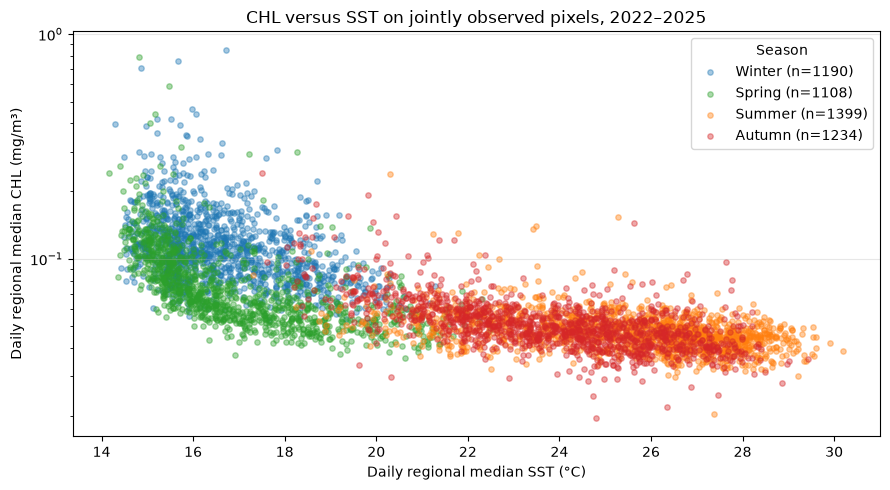

In [12]:
spatial_dims = ["latitude", "longitude"]

paired = (
    analysis_mask
    & np.isfinite(data["chl"])
    & np.isfinite(data["sst_c"])
)

paired_days = paired.any(dim=spatial_dims)

paired_daily = (
    data[["chl", "sst_c"]]
    .where(paired)
    .isel(time=np.flatnonzero(paired_days.values))
    .median(dim=spatial_dims, skipna=True)
    .to_dataframe()[["chl", "sst_c"]]
    .dropna()
)

paired_daily["season"] = (
    data.time.dt.season.sel(time=paired_daily.index).values
)

fig, ax = plt.subplots(figsize=(9, 5))

for season, name, colour in [
    ("DJF", "Winter", "tab:blue"),
    ("MAM", "Spring", "tab:green"),
    ("JJA", "Summer", "tab:orange"),
    ("SON", "Autumn", "tab:red"),
]:
    subset = paired_daily[paired_daily["season"] == season]
    ax.scatter(
        subset["sst_c"], subset["chl"],
        s=15, alpha=0.4, color=colour,
        label=f"{name} (n={len(subset)})",
    )

ax.set_yscale("log")
ax.set_xlabel("Daily regional median SST (°C)")
ax.set_ylabel("Daily regional median CHL (mg/m³)")
ax.set_title("CHL versus SST on jointly observed pixels, 2022–2025")
ax.legend(title="Season")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

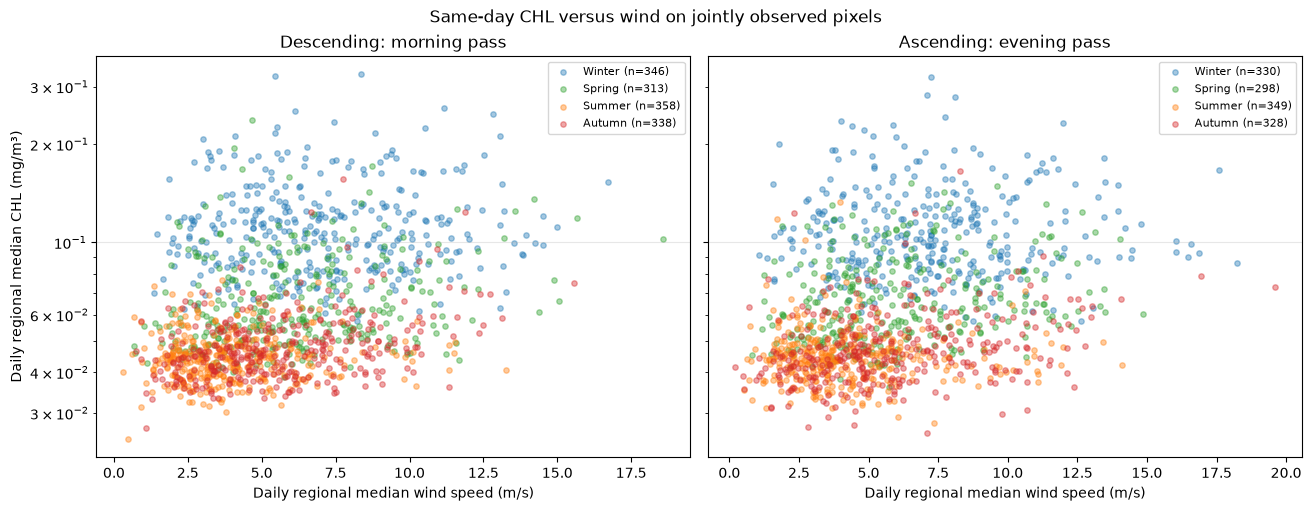

In [13]:
seasons = [
    ("DJF", "Winter", "tab:blue"),
    ("MAM", "Spring", "tab:green"),
    ("JJA", "Summer", "tab:orange"),
    ("SON", "Autumn", "tab:red"),
]

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), sharey=True, constrained_layout=True
)

for ax, wind_var, title in zip(
    axes,
    ["wind_speed_des", "wind_speed_asc"],
    ["Descending: morning pass", "Ascending: evening pass"],
):
    paired = (
        analysis_mask
        & np.isfinite(data["chl"])
        & np.isfinite(data[wind_var])
    )
    valid_days = paired.any(dim=spatial_dims)

    points = (
        data[["chl", wind_var]]
        .where(paired)
        .isel(time=np.flatnonzero(valid_days.values))
        .median(dim=spatial_dims, skipna=True)
        .to_dataframe()[["chl", wind_var]]
        .dropna()
    )
    points["season"] = (
        data.time.dt.season.sel(time=points.index).values
    )

    for season, name, colour in seasons:
        subset = points[points["season"] == season]
        ax.scatter(
            subset[wind_var], subset["chl"],
            s=15, alpha=0.4, color=colour,
            label=f"{name} (n={len(subset)})",
        )

    ax.set_yscale("log")
    ax.set_xlabel("Daily regional median wind speed (m/s)")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Daily regional median CHL (mg/m³)")
fig.suptitle("Same-day CHL versus wind on jointly observed pixels")
plt.show()

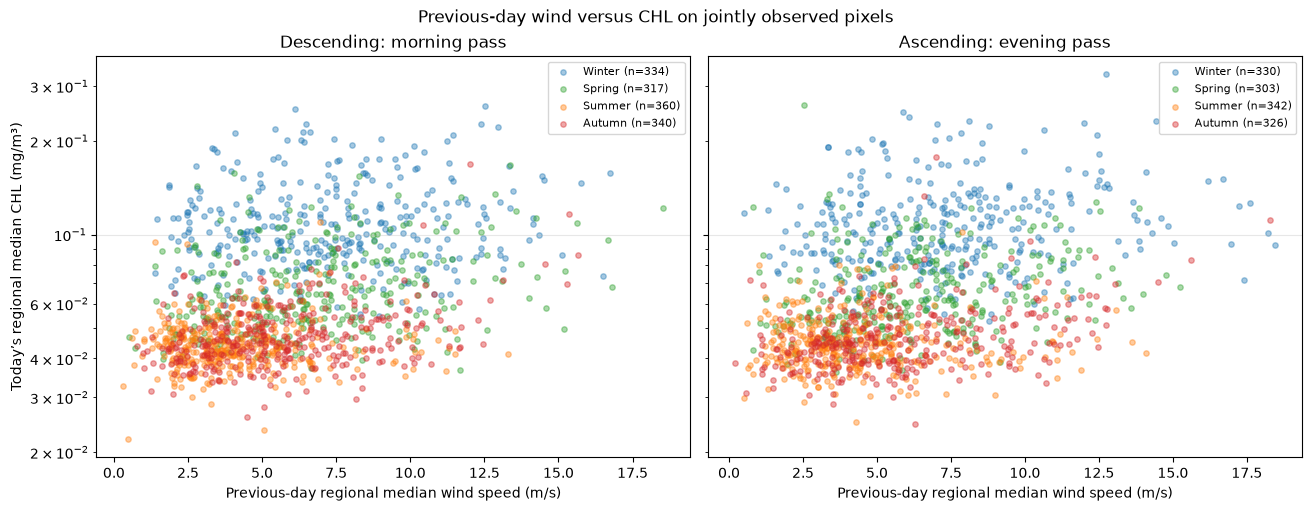

In [14]:
lag_days = 1

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), sharey=True, constrained_layout=True
)

for ax, wind_var, title in zip(
    axes,
    ["wind_speed_des", "wind_speed_asc"],
    ["Descending: morning pass", "Ascending: evening pass"],
):
    # Positive shift places yesterday's wind against today's CHL.
    lagged = data[["chl", wind_var]].assign(
        {wind_var: data[wind_var].shift(time=lag_days)}
    )

    paired = (
        analysis_mask
        & np.isfinite(lagged["chl"])
        & np.isfinite(lagged[wind_var])
    )
    valid_days = paired.any(dim=spatial_dims)

    points = (
        lagged.where(paired)
        .isel(time=np.flatnonzero(valid_days.values))
        .median(dim=spatial_dims, skipna=True)
        .to_dataframe()[["chl", wind_var]]
        .dropna()
    )
    points["season"] = (
        data.time.dt.season.sel(time=points.index).values
    )

    for season, name, colour in seasons:
        subset = points[points["season"] == season]
        ax.scatter(
            subset[wind_var], subset["chl"],
            s=15, alpha=0.4, color=colour,
            label=f"{name} (n={len(subset)})",
        )

    ax.set_yscale("log")
    ax.set_xlabel("Previous-day regional median wind speed (m/s)")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Today’s regional median CHL (mg/m³)")
fig.suptitle("Previous-day wind versus CHL on jointly observed pixels")
plt.show()

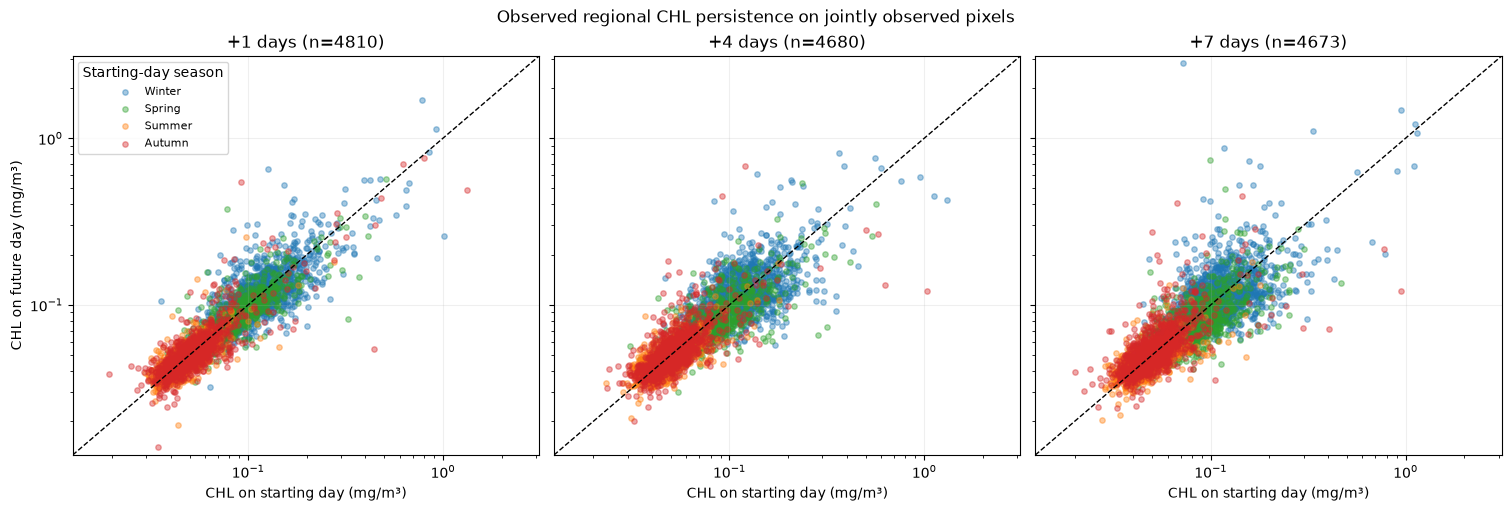

In [15]:
fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), sharex=True, sharey=True,
    constrained_layout=True,
)
plot_limits = []

for ax, horizon in zip(axes, [1, 4, 7]):
    comparison = xr.Dataset({
        "chl_now": data["chl"],
        "chl_future": data["chl"].shift(time=-horizon),
    })

    paired = (
        analysis_mask
        & np.isfinite(comparison["chl_now"])
        & np.isfinite(comparison["chl_future"])
        & (comparison["chl_now"] > 0)
        & (comparison["chl_future"] > 0)
    )
    valid_days = paired.any(dim=spatial_dims)

    points = (
        comparison.where(paired)
        .isel(time=np.flatnonzero(valid_days.values))
        .median(dim=spatial_dims, skipna=True)
        .to_dataframe()[["chl_now", "chl_future"]]
        .dropna()
    )
    points["season"] = (
        data.time.dt.season.sel(time=points.index).values
    )

    for season, name, colour in seasons:
        subset = points[points["season"] == season]
        ax.scatter(
            subset["chl_now"], subset["chl_future"],
            s=15, alpha=0.4, color=colour, label=name,
        )

    plot_limits.extend(points[["chl_now", "chl_future"]].values.ravel())
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("CHL on starting day (mg/m³)")
    ax.set_title(f"+{horizon} days (n={len(points)})")
    ax.grid(alpha=0.2)

low, high = np.min(plot_limits) * 0.9, np.max(plot_limits) * 1.1

for ax in axes:
    ax.plot([low, high], [low, high], "k--", linewidth=1)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)

axes[0].set_ylabel("CHL on future day (mg/m³)")
axes[0].legend(title="Starting-day season", fontsize=8)
fig.suptitle("Observed regional CHL persistence on jointly observed pixels")
plt.show()

In [16]:
rows = []

for season, name, _ in seasons:
    subset = points[points["season"] == season]

    predicted = subset["chl_now"]       # Unchanged-value estimate
    observed = subset["chl_future"]     # Observed CHL seven days later
    error = predicted - observed

    rows.append({
        "Season": name,
        "Paired days": len(subset),
        "MAE (mg/m³)": np.abs(error).mean(),
        "RMSE (mg/m³)": np.sqrt((error ** 2).mean()),
        "Median absolute relative error (%)":
            (100 * np.abs(error) / observed).median(),
    })

persistence_summary = pd.DataFrame(rows).set_index("Season")

display(persistence_summary.style.format({
    "Paired days": "{:,.0f}",
    "MAE (mg/m³)": "{:.4f}",
    "RMSE (mg/m³)": "{:.4f}",
    "Median absolute relative error (%)": "{:.1f}",
}))

,Paired days,MAE (mg/m³),RMSE (mg/m³),Median absolute relative error (%)
Season,,,,
Winter,"1,216",0.0399,0.1060,21.0
Spring,984,0.0178,0.0374,14.7
Summer,"1,326",0.0061,0.0097,9.4
Autumn,"1,147",0.0127,0.0399,12.3


In [17]:
rows = []

for year in np.unique(data.time.dt.year.values):
    yearly = data.sel(time=str(year))

    for variable, name in [
        ("wind_asc_valid", "Ascending"),
        ("wind_des_valid", "Descending"),
        ("wind_any_valid", "Either pass"),
    ]:
        valid = (yearly[variable] == 1) & analysis_mask
        daily_coverage = (
            100 * valid.sum(dim=spatial_dims) / included
        )

        rows.append({
            "Year": int(year),
            "Pass": name,
            "Days in year": yearly.sizes["time"],
            "Days with observations":
                int(valid.any(dim=spatial_dims).sum().item()),
            "Mean daily coverage (%)":
                float(daily_coverage.mean().item()),
        })

wind_year_summary = pd.DataFrame(rows).set_index(["Year", "Pass"])

display(wind_year_summary.style.format({
    "Days in year": "{:,.0f}",
    "Days with observations": "{:,.0f}",
    "Mean daily coverage (%)": "{:.1f}",
}))

In [19]:
suffix = "2019-01-01_2025-12-31_13.9_15.2_35.55_36.9.nc"

raw_wind = {
    name: xr.open_dataset(
        BASE / "data/raw" / f"wind_{name}_my_202311_{suffix}"
    )
    for name in ["ascending", "descending"]
}

rows = []

for name, ds in raw_wind.items():
    valid = (
        np.isfinite(ds["wind_speed"])
        & np.isfinite(ds["eastward_wind"])
        & np.isfinite(ds["northward_wind"])
    )

    native_dims = [dim for dim in valid.dims if dim != "time"]
    daily_cells = valid.sum(dim=native_dims)

    for year in np.unique(ds.time.dt.year.values):
        yearly = daily_cells.sel(time=str(year))

        rows.append({
            "Year": int(year),
            "Pass": name.capitalize(),
            "Days with raw observations":
                int((yearly > 0).sum().item()),
            "Mean valid native cells/day":
                float(yearly.mean().item()),
        })

raw_wind_summary = pd.DataFrame(rows).set_index(["Year", "Pass"])

display(raw_wind_summary.style.format({
    "Days with raw observations": "{:,.0f}",
    "Mean valid native cells/day": "{:.2f}",
}))

,,Days with raw observations,Mean valid native cells/day
Year,Pass,,
2019,Ascending,217,46.13
2020,Ascending,217,45.80
2021,Ascending,217,45.61
2022,Ascending,216,46.59
2023,Ascending,212,53.38
2024,Ascending,213,53.89
2025,Ascending,216,53.79
2019,Descending,225,46.15
2020,Descending,228,45.55


In [20]:
reject_flags = {
    "distance_to_gmf_too_large",
    "wind_inversion_not_successful",
    "variational_quality_control_fails",
    "knmi_quality_control_fails",
    "product_monitoring_event_flag",
    "not_enough_good_sigma0_for_wind_retrieval",
}

rows = []

for name, ds in raw_wind.items():
    qc_names = [
        variable for variable in ds.data_vars
        if "knmi_quality_control_fails"
        in str(ds[variable].attrs.get("flag_meanings", ""))
    ]
    if len(qc_names) != 1:
        raise ValueError(f"{name}: expected one wind QC variable, found {qc_names}")

    qc = ds[qc_names[0]]
    meanings = qc.attrs["flag_meanings"].split()
    masks = np.asarray(qc.attrs["flag_masks"], dtype="uint64")

    reject_mask = 0
    for meaning, mask in zip(meanings, masks):
        if meaning in reject_flags:
            reject_mask |= int(mask)

    before = (
        np.isfinite(ds["wind_speed"])
        & np.isfinite(ds["eastward_wind"])
        & np.isfinite(ds["northward_wind"])
        & (ds["wind_speed"] >= 0)
    )
    retained = (
        before
        & qc.notnull()
        & ((qc.fillna(0).astype("uint64") & reject_mask) == 0)
    )

    for year in np.unique(ds.time.dt.year.values):
        raw_count = int(before.sel(time=str(year)).sum().item())
        kept_count = int(retained.sel(time=str(year)).sum().item())

        rows.append({
            "Year": int(year),
            "Pass": name.capitalize(),
            "Raw pixel-days": raw_count,
            "Retained pixel-days": kept_count,
            "Retained (%)": 100 * kept_count / raw_count
                if raw_count else np.nan,
        })

wind_qc_summary = pd.DataFrame(rows).set_index(["Year", "Pass"])

display(wind_qc_summary.style.format({
    "Raw pixel-days": "{:,.0f}",
    "Retained pixel-days": "{:,.0f}",
    "Retained (%)": "{:.1f}",
}))

,,Raw pixel-days,Retained pixel-days,Retained (%)
Year,Pass,,,
2019,Ascending,"16,837","12,055",71.6
2020,Ascending,"16,764","12,076",72.0
2021,Ascending,"16,649","11,949",71.8
2022,Ascending,"17,006","12,257",72.1
2023,Ascending,"19,483","15,543",79.8
2024,Ascending,"19,724","15,752",79.9
2025,Ascending,"19,633","15,538",79.1
2019,Descending,"16,843","12,293",73.0
2020,Descending,"16,670","12,071",72.4
